<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_089_optimizers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 89/365 — Optimizers: SGD vs Momentum vs RMSProp vs Adam

Backpropagation gives us gradients.

The **optimizer** decides how those gradients should update the weights.


In [1]:
import numpy as np
import matplotlib.pyplot as plt


## 1. SGD

Basic rule:

`w = w - learning_rate × gradient`

SGD uses the current gradient directly.

It is simple, but can oscillate on uneven loss surfaces.


## 2. Momentum

Momentum remembers recent gradient direction.

Intuition:

**SGD = walk downhill**

**Momentum = roll a ball downhill**

It can reduce zig-zagging and accelerate progress in consistent directions.


## 3. RMSProp

RMSProp tracks recent squared gradients.

Parameters with repeatedly large gradients get smaller effective steps.

Parameters with smaller gradients can get relatively larger steps.

So learning rates adapt per parameter.


## 4. Adam

Adam combines:

- Momentum-style gradient averaging
- RMSProp-style adaptive scaling

That makes Adam a strong default optimizer for many deep-learning tasks.


## 5. Tiny SGD example

Suppose:

`weight = 2`

`gradient = 3`

`learning rate = 0.1`

Then:

`new_weight = 2 - 0.1 × 3 = 1.7`


In [2]:
weight=2.0
gradient=3.0
learning_rate=0.1

new_weight=weight-learning_rate*gradient

print("Updated weight:",new_weight)


Updated weight: 1.7


## 6. Compare optimizer paths on a simple loss surface


In [3]:
def grad(p):
    return np.array([2*p[0], 8*p[1]])

start=np.array([4.5,3.2])

def sgd():
    p=start.copy()
    path=[p.copy()]
    for _ in range(30):
        p=p-0.08*grad(p)
        path.append(p.copy())
    return np.array(path)

def momentum():
    p=start.copy()
    v=np.zeros(2)
    path=[p.copy()]
    for _ in range(30):
        g=grad(p)
        v=0.9*v+g
        p=p-0.04*v
        path.append(p.copy())
    return np.array(path)

def rmsprop():
    p=start.copy()
    s=np.zeros(2)
    path=[p.copy()]
    for _ in range(30):
        g=grad(p)
        s=0.9*s+0.1*(g**2)
        p=p-0.12*g/(np.sqrt(s)+1e-8)
        path.append(p.copy())
    return np.array(path)

def adam():
    p=start.copy()
    m=np.zeros(2)
    v=np.zeros(2)
    path=[p.copy()]

    for t in range(1,31):
        g=grad(p)
        m=0.9*m+0.1*g
        v=0.999*v+0.001*(g**2)

        m_hat=m/(1-0.9**t)
        v_hat=v/(1-0.999**t)

        p=p-0.15*m_hat/(np.sqrt(v_hat)+1e-8)
        path.append(p.copy())

    return np.array(path)


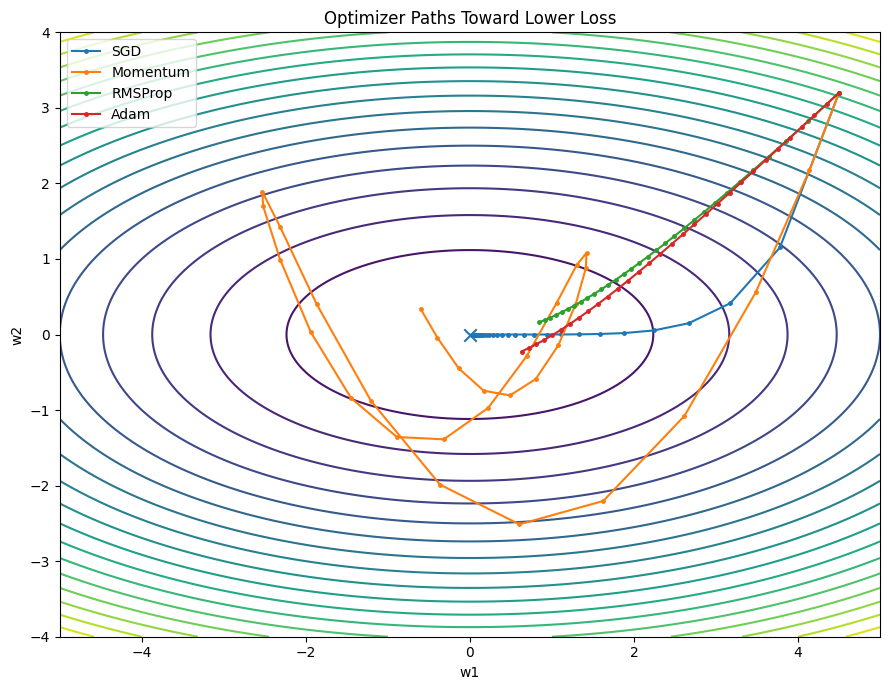

In [4]:
paths={
    "SGD":sgd(),
    "Momentum":momentum(),
    "RMSProp":rmsprop(),
    "Adam":adam()
}

xx=np.linspace(-5,5,220)
yy=np.linspace(-4,4,220)

X,Y=np.meshgrid(xx,yy)
Z=X**2+4*Y**2

plt.figure(figsize=(9,7))
plt.contour(X,Y,Z,levels=18)

for name,path in paths.items():
    plt.plot(
        path[:,0],
        path[:,1],
        marker="o",
        markersize=2.5,
        label=name
    )

plt.scatter([0],[0],s=80,marker="x")
plt.xlabel("w1")
plt.ylabel("w2")
plt.title("Optimizer Paths Toward Lower Loss")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Easy comparison

### SGD
Uses the current gradient.

### Momentum
Adds memory of previous gradients.

### RMSProp
Adapts the effective learning rate for each parameter.

### Adam
Combines momentum and adaptive scaling.

A common practical starting point is **Adam**, but SGD + Momentum can still be extremely strong when tuned well.


## 8. Learning rate still matters

Adam does not remove the need for a sensible learning rate.

Too small:

training becomes slow.

Too large:

training may become unstable.

Optimizer and learning rate should be considered together.


## Simple takeaway

Backpropagation computes gradients.

The optimizer decides how those gradients change the weights.

> **SGD follows the gradient. Momentum remembers direction. RMSProp adapts step sizes. Adam combines both ideas.**


## References

- Adam — Kingma & Ba:
  https://arxiv.org/abs/1412.6980

- PyTorch Optimizers:
  https://pytorch.org/docs/stable/optim.html

- Deep Learning:
  https://www.deeplearningbook.org/
